In [1]:
import numpy as np
from collections import defaultdict
import random
import matplotlib.pyplot as plt
import time

In [2]:
import gymnasium as gym
env = gym.make("MountainCar-v0")

In [3]:
def epsilon_greedy(epsilon, Q_values, state):
    n = np.random.rand()
    if n < epsilon:
        action = np.random.choice([0, 1, 2])
    else:
        action = np.argmax(Q_values[state])
    return action

In [4]:
def epsilon_decay(epsilon, episode, min_epsilon = 0.01, decay_step = 0.05, decay_start = 0, decay_interval = 24):
    if episode > decay_start and (episode - decay_start) % decay_interval == 0:
        epsilon = np.round(max(min_epsilon, epsilon - decay_step), 2)
    return epsilon

In [5]:
def discretize_state(state):
    digitize_0 = np.linspace(-1.2, 0.6, 10)
    digitize_1 = np.linspace(-0.07, 0.07, 10)
    state_0 = np.digitize(state[0], digitize_0) - 1
    state_1 = np.digitize(state[1], digitize_1) - 1
    return (state_0, state_1)

In [6]:
def Q_Learning(alpha, gamma, epsilon, num_epi):
    Q_values = np.zeros((10, 10, 3))
    episodes = []
    for e in range(num_epi):
        print('Episode:', e + 1, ', Epsilon:', epsilon)
        episode = []
        state, _ = env.reset()
        state = discretize_state(state)
        action = epsilon_greedy(epsilon, Q_values, state)
        done = False
        while not done:
            next_state, reward, done, truncated, info = env.step(action)
            next_state = discretize_state(next_state)
            next_action = epsilon_greedy(epsilon, Q_values, next_state)
            Q_values[state[0], state[1], action] = Q_values[state[0], state[1], action] + alpha * (reward + (gamma * np.max(Q_values[next_state[0], next_state[1]]) - Q_values[state[0], state[1], action]))
            episode.append((state, action, reward))
            state = next_state
            action = next_action
        epsilon = epsilon_decay(epsilon, e)
        episodes.append(episode)
    return episodes, Q_values

In [7]:
def episode_return(episodes):
    epi_returns = []
    for e in episodes:
        epi_return = 0
        i = 0
        for _, _, reward in e:
            epi_return += reward
            i += 1
        epi_returns.append(epi_return)
    return epi_returns

In [8]:
def simulate(Q_values):
    curr = time.time()
    state, _ = env.reset()
    state = discretize_state(state)
    action = epsilon_greedy(0, Q_values, state)
    done = False
    while not done:
        next_state, _, done, truncated, _ = env.step(action)
        next_state = discretize_state(next_state)
        next_action = epsilon_greedy(0, Q_values, next_state)
        action = next_action
    end = time.time()
    print('Time taken to finish episode using learned policy:', end - curr, 'seconds')

In [9]:
episodes, Q_values = Q_Learning(0.1, 0.95, 1, 500)

Episode: 1 , Epsilon: 1
Episode: 2 , Epsilon: 1
Episode: 3 , Epsilon: 1
Episode: 4 , Epsilon: 1
Episode: 5 , Epsilon: 1
Episode: 6 , Epsilon: 1
Episode: 7 , Epsilon: 1
Episode: 8 , Epsilon: 1
Episode: 9 , Epsilon: 1
Episode: 10 , Epsilon: 1
Episode: 11 , Epsilon: 1
Episode: 12 , Epsilon: 1
Episode: 13 , Epsilon: 1
Episode: 14 , Epsilon: 1
Episode: 15 , Epsilon: 1
Episode: 16 , Epsilon: 1
Episode: 17 , Epsilon: 1
Episode: 18 , Epsilon: 1
Episode: 19 , Epsilon: 1
Episode: 20 , Epsilon: 1
Episode: 21 , Epsilon: 1
Episode: 22 , Epsilon: 1
Episode: 23 , Epsilon: 1
Episode: 24 , Epsilon: 1
Episode: 25 , Epsilon: 1
Episode: 26 , Epsilon: 0.95
Episode: 27 , Epsilon: 0.95
Episode: 28 , Epsilon: 0.95
Episode: 29 , Epsilon: 0.95
Episode: 30 , Epsilon: 0.95
Episode: 31 , Epsilon: 0.95
Episode: 32 , Epsilon: 0.95
Episode: 33 , Epsilon: 0.95
Episode: 34 , Epsilon: 0.95
Episode: 35 , Epsilon: 0.95
Episode: 36 , Epsilon: 0.95
Episode: 37 , Epsilon: 0.95
Episode: 38 , Epsilon: 0.95
Episode: 39 , Epsilo

Episode: 295 , Epsilon: 0.4
Episode: 296 , Epsilon: 0.4
Episode: 297 , Epsilon: 0.4
Episode: 298 , Epsilon: 0.4
Episode: 299 , Epsilon: 0.4
Episode: 300 , Epsilon: 0.4
Episode: 301 , Epsilon: 0.4
Episode: 302 , Epsilon: 0.4
Episode: 303 , Epsilon: 0.4
Episode: 304 , Epsilon: 0.4
Episode: 305 , Epsilon: 0.4
Episode: 306 , Epsilon: 0.4
Episode: 307 , Epsilon: 0.4
Episode: 308 , Epsilon: 0.4
Episode: 309 , Epsilon: 0.4
Episode: 310 , Epsilon: 0.4
Episode: 311 , Epsilon: 0.4
Episode: 312 , Epsilon: 0.4
Episode: 313 , Epsilon: 0.4
Episode: 314 , Epsilon: 0.35
Episode: 315 , Epsilon: 0.35
Episode: 316 , Epsilon: 0.35
Episode: 317 , Epsilon: 0.35
Episode: 318 , Epsilon: 0.35
Episode: 319 , Epsilon: 0.35
Episode: 320 , Epsilon: 0.35
Episode: 321 , Epsilon: 0.35
Episode: 322 , Epsilon: 0.35
Episode: 323 , Epsilon: 0.35
Episode: 324 , Epsilon: 0.35
Episode: 325 , Epsilon: 0.35
Episode: 326 , Epsilon: 0.35
Episode: 327 , Epsilon: 0.35
Episode: 328 , Epsilon: 0.35
Episode: 329 , Epsilon: 0.35
Epis

In [10]:
total_returns = episode_return(episodes)

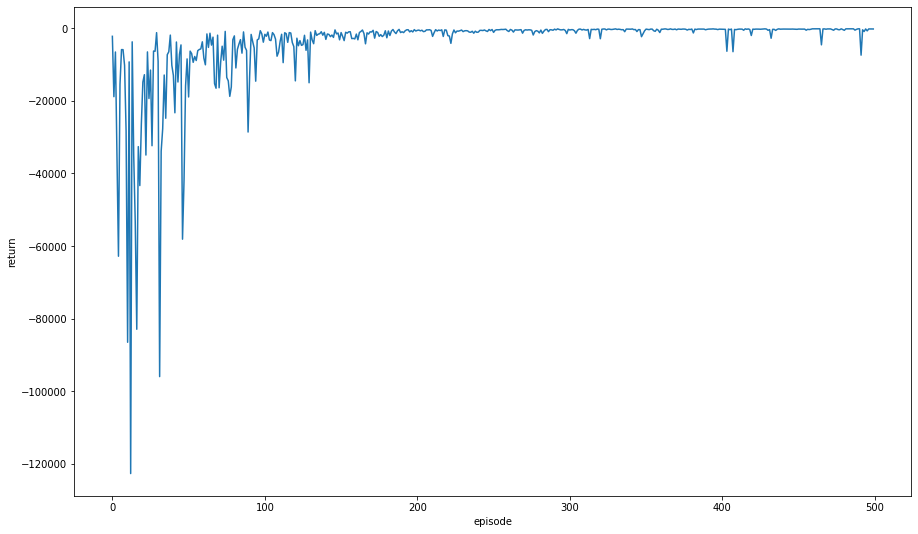

In [11]:
plt.figure(figsize = (15, 9))
plt.plot(total_returns)
plt.xlabel('episode')
plt.ylabel('return')
plt.show()

In [12]:
simulate(Q_values)

Time taken to finish episode using learned policy: 0.03425264358520508 seconds


In [13]:
len(episodes[0]), len(episodes[150]), len(episodes[499])

(2221, 1186, 197)